In [11]:
import pandas as pd
import numpy as np

# Import plotting libraries

import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("../data/retail_store_inventory.csv")

# Display first 5 rows
df.head()

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Discount,Weather Condition,Holiday/Promotion,Competitor Pricing,Seasonality
0,2022-01-01,S001,P0001,Groceries,North,231,127,55,135.47,33.50,20,Rainy,0,29.69,Autumn
1,2022-01-01,S001,P0002,Toys,South,204,150,66,144.04,63.01,20,Sunny,0,66.16,Autumn
2,2022-01-01,S001,P0003,Toys,West,102,65,51,74.02,27.99,10,Sunny,1,31.32,Summer
3,2022-01-01,S001,P0004,Toys,North,469,61,164,62.18,32.72,10,Cloudy,1,34.74,Autumn
4,2022-01-01,S001,P0005,Electronics,East,166,14,135,9.26,73.64,0,Sunny,0,68.95,Summer


In [3]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()


Dataset Shape: (73100, 15)

Column Names:
['Date', 'Store ID', 'Product ID', 'Category', 'Region', 'Inventory Level', 'Units Sold', 'Units Ordered', 'Demand Forecast', 'Price', 'Discount', 'Weather Condition', 'Holiday/Promotion', 'Competitor Pricing', 'Seasonality']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 73100 entries, 0 to 73099
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Date                73100 non-null  object 
 1   Store ID            73100 non-null  object 
 2   Product ID          73100 non-null  object 
 3   Category            73100 non-null  object 
 4   Region              73100 non-null  object 
 5   Inventory Level     73100 non-null  int64  
 6   Units Sold          73100 non-null  int64  
 7   Units Ordered       73100 non-null  int64  
 8   Demand Forecast     73100 non-null  float64
 9   Price               73100 non-null  float64
 10  Discount

In [4]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

Missing Values:
Date                  0
Store ID              0
Product ID            0
Category              0
Region                0
Inventory Level       0
Units Sold            0
Units Ordered         0
Demand Forecast       0
Price                 0
Discount              0
Weather Condition     0
Holiday/Promotion     0
Competitor Pricing    0
Seasonality           0
dtype: int64

Duplicate Rows: 0


In [5]:
# Make a copy for cleaning
df_clean = df.copy()

# Convert Date to datetime
df_clean["Date"] = pd.to_datetime(df_clean["Date"])

# Check data types after conversion
print(df_clean.dtypes)

Date                  datetime64[ns]
Store ID                      object
Product ID                    object
Category                      object
Region                        object
Inventory Level                int64
Units Sold                     int64
Units Ordered                  int64
Demand Forecast              float64
Price                        float64
Discount                       int64
Weather Condition             object
Holiday/Promotion              int64
Competitor Pricing           float64
Seasonality                   object
dtype: object


In [6]:
# Check duplicate rows again
print("Duplicate rows:", df_clean.duplicated().sum())

# Check missing values again
print("\nMissing values:")
print(df_clean.isnull().sum())

Duplicate rows: 0

Missing values:
Date                  0
Store ID              0
Product ID            0
Category              0
Region                0
Inventory Level       0
Units Sold            0
Units Ordered         0
Demand Forecast       0
Price                 0
Discount              0
Weather Condition     0
Holiday/Promotion     0
Competitor Pricing    0
Seasonality           0
dtype: int64


In [7]:
# Check unique values of categorical columns
categorical_columns = [
    "Store ID",
    "Product ID",
    "Category",
    "Region",
    "Weather Condition",
    "Seasonality"
]

for col in categorical_columns:
    print(f"\n{col}:")
    print(df_clean[col].unique())


Store ID:
['S001' 'S002' 'S003' 'S004' 'S005']

Product ID:
['P0001' 'P0002' 'P0003' 'P0004' 'P0005' 'P0006' 'P0007' 'P0008' 'P0009'
 'P0010' 'P0011' 'P0012' 'P0013' 'P0014' 'P0015' 'P0016' 'P0017' 'P0018'
 'P0019' 'P0020']

Category:
['Groceries' 'Toys' 'Electronics' 'Furniture' 'Clothing']

Region:
['North' 'South' 'West' 'East']

Weather Condition:
['Rainy' 'Sunny' 'Cloudy' 'Snowy']

Seasonality:
['Autumn' 'Summer' 'Winter' 'Spring']


In [8]:
# Category-wise total sales

category_sales = (
    df_clean.groupby("Category")["Units Sold"]
    .sum()
    .sort_values(ascending=False)
)

print(category_sales)

Category
Furniture      2025017
Groceries      2000482
Clothing       1999166
Toys           1990485
Electronics    1960432
Name: Units Sold, dtype: int64


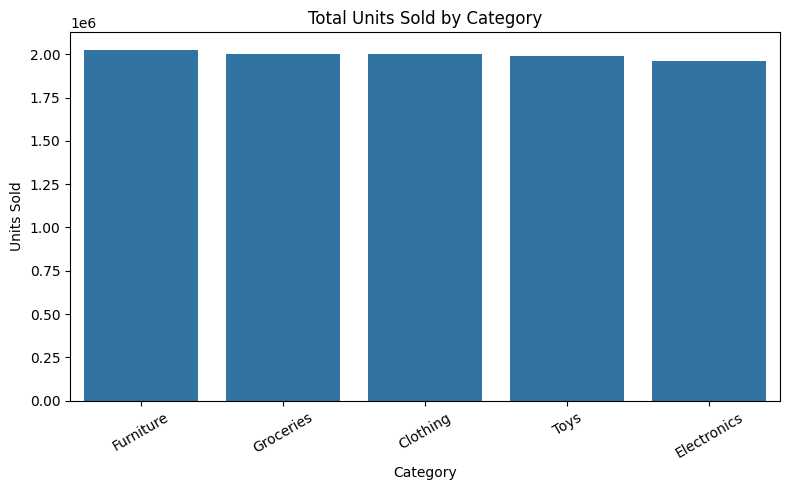

In [12]:
# Category-wise sales chart

plt.figure(figsize=(8, 5))

sns.barplot(
    x=category_sales.index,
    y=category_sales.values
)

plt.title("Total Units Sold by Category")
plt.xlabel("Category")
plt.ylabel("Units Sold")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [14]:
# Region-wise inventory

region_inventory = (
    df_clean.groupby("Region")["Inventory Level"]
    .sum()
    .sort_values(ascending=False)
)

print(region_inventory)

Region
East     5051345
South    5037406
North    5008993
West     4966004
Name: Inventory Level, dtype: int64


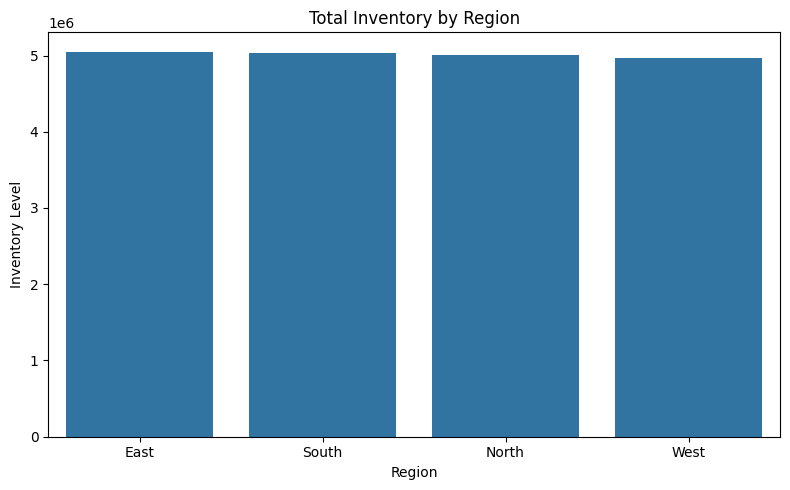

In [16]:
# Region-wise inventory chart

plt.figure(figsize=(8, 5))

sns.barplot(
    x=region_inventory.index,
    y=region_inventory.values
)

plt.title("Total Inventory by Region")
plt.xlabel("Region")
plt.ylabel("Inventory Level")
plt.tight_layout()
plt.show()

In [17]:
# Inventory and sales relationship

print(df_clean[["Inventory Level", "Units Sold"]].corr())

                 Inventory Level  Units Sold
Inventory Level         1.000000    0.589995
Units Sold              0.589995    1.000000


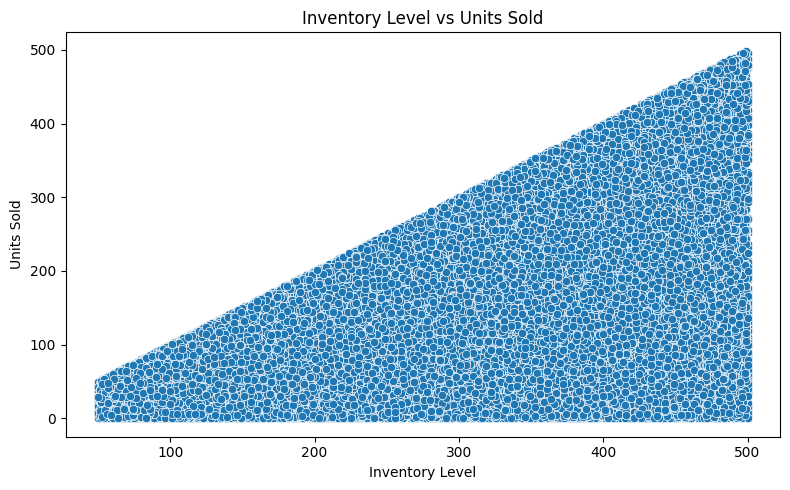

In [18]:
# Inventory vs sales chart

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df_clean,
    x="Inventory Level",
    y="Units Sold"
)

plt.title("Inventory Level vs Units Sold")
plt.xlabel("Inventory Level")
plt.ylabel("Units Sold")
plt.tight_layout()
plt.show()

In [19]:
# Demand forecast and actual sales relationship

print(df_clean[["Demand Forecast", "Units Sold"]].corr())

                 Demand Forecast  Units Sold
Demand Forecast         1.000000    0.996853
Units Sold              0.996853    1.000000


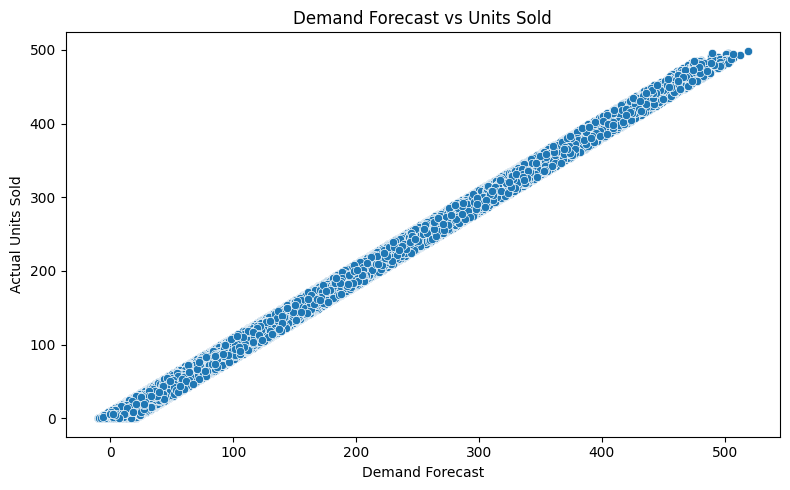

In [20]:
# Demand forecast vs actual sales

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df_clean,
    x="Demand Forecast",
    y="Units Sold"
)

plt.title("Demand Forecast vs Units Sold")
plt.xlabel("Demand Forecast")
plt.ylabel("Actual Units Sold")
plt.tight_layout()
plt.show()

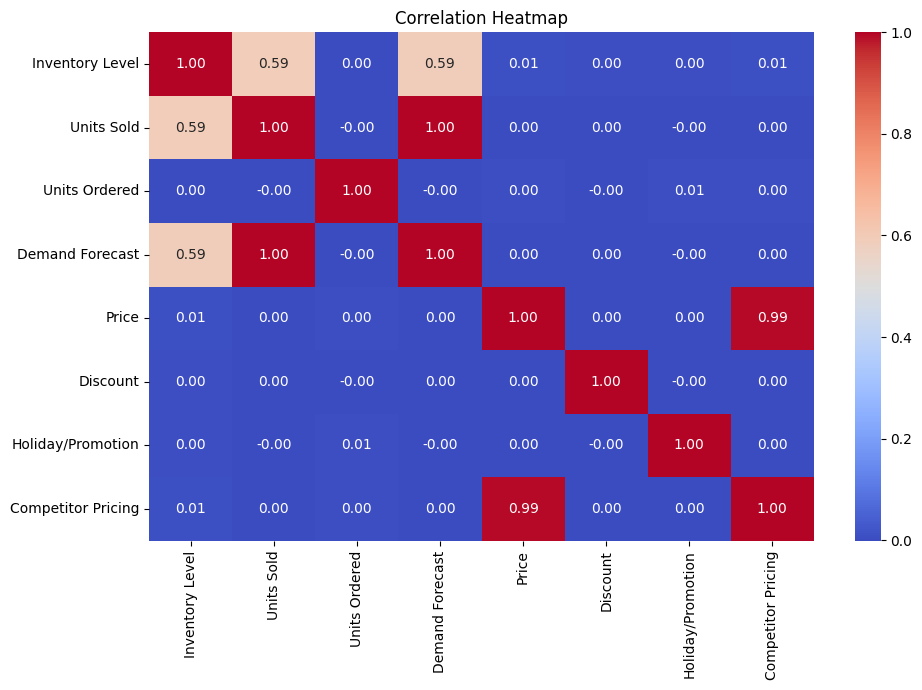

In [21]:
# Numerical feature correlation

correlation = df_clean.select_dtypes(include="number").corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [22]:
# Promotion-wise sales

promotion_sales = df_clean.groupby("Holiday/Promotion")["Units Sold"].mean()

print(promotion_sales)

Holiday/Promotion
0    136.505375
1    136.423926
Name: Units Sold, dtype: float64


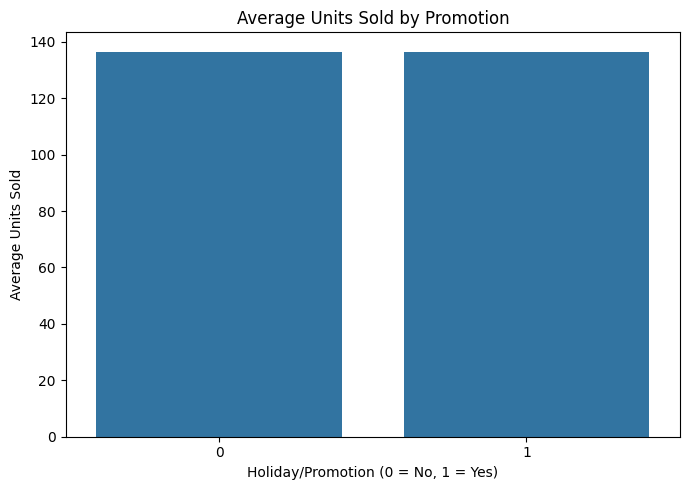

In [23]:
# Promotion impact on sales

plt.figure(figsize=(7, 5))

sns.barplot(
    x=promotion_sales.index,
    y=promotion_sales.values
)

plt.title("Average Units Sold by Promotion")
plt.xlabel("Holiday/Promotion (0 = No, 1 = Yes)")
plt.ylabel("Average Units Sold")
plt.tight_layout()
plt.show()

In [24]:
# Season-wise sales

season_sales = df_clean.groupby("Seasonality")["Units Sold"].mean()

print(season_sales)

Seasonality
Autumn    137.782444
Spring    135.826828
Summer    135.428298
Winter    136.830790
Name: Units Sold, dtype: float64


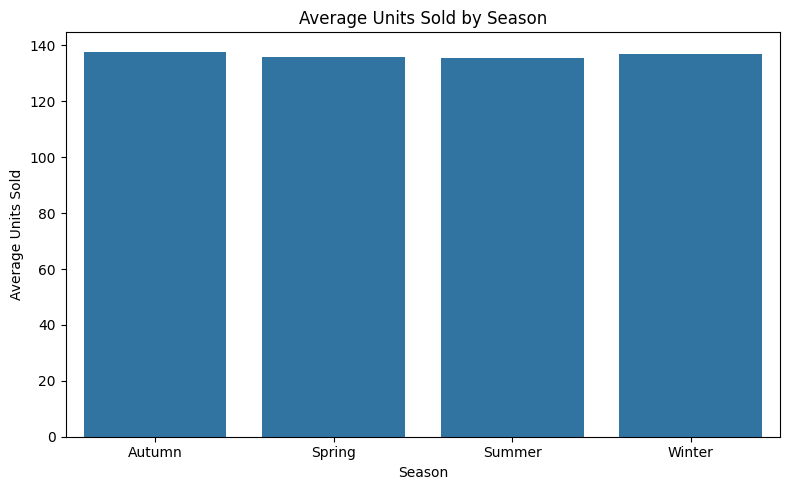

In [25]:
# Seasonality impact on sales

plt.figure(figsize=(8, 5))

sns.barplot(
    x=season_sales.index,
    y=season_sales.values
)

plt.title("Average Units Sold by Season")
plt.xlabel("Season")
plt.ylabel("Average Units Sold")
plt.tight_layout()
plt.show()

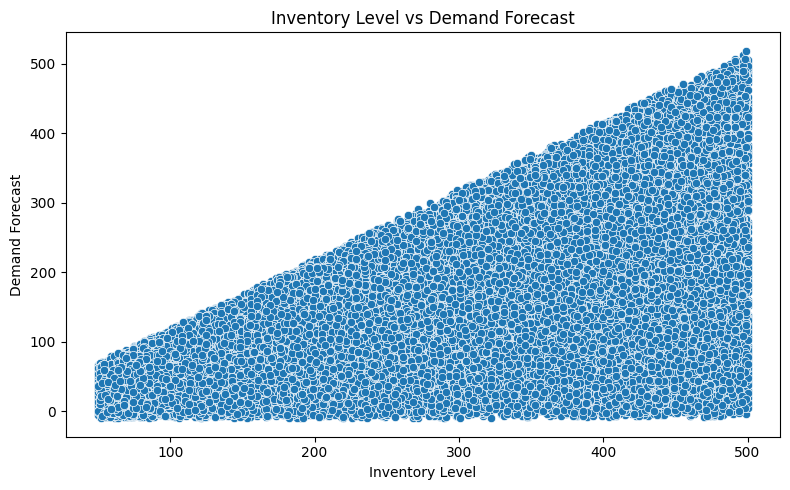

In [26]:
# Inventory level vs demand forecast

plt.figure(figsize=(8, 5))

sns.scatterplot(
    x="Inventory Level",
    y="Demand Forecast",
    data=df_clean
)

plt.title("Inventory Level vs Demand Forecast")
plt.xlabel("Inventory Level")
plt.ylabel("Demand Forecast")
plt.tight_layout()
plt.show()

In [27]:
# Top 10 products by sales

product_sales = df_clean.groupby("Product ID")["Units Sold"].sum().sort_values(ascending=False).head(10)

print(product_sales)

Product ID
P0016    508472
P0020    507708
P0014    507622
P0015    507283
P0005    503648
P0009    502086
P0013    500619
P0017    500510
P0011    499362
P0007    499321
Name: Units Sold, dtype: int64


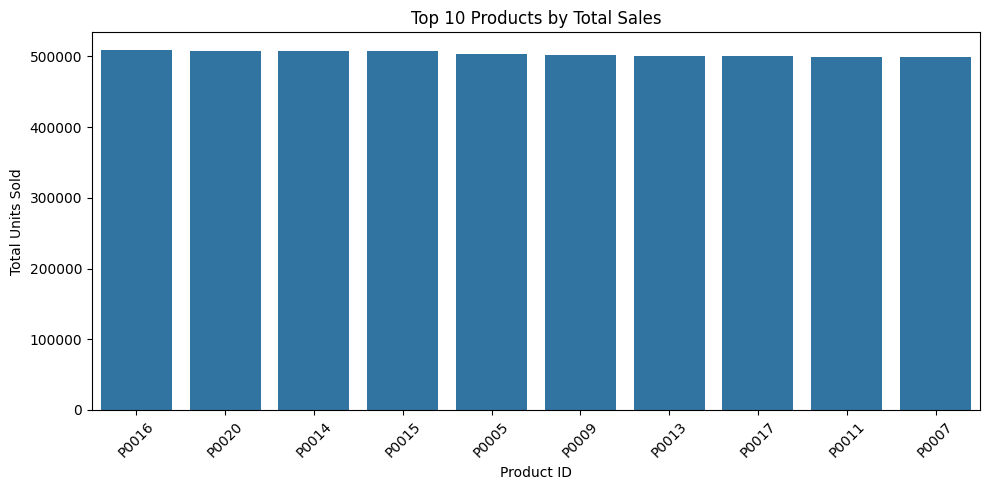

In [28]:
# Top 10 products sales chart

plt.figure(figsize=(10, 5))

sns.barplot(
    x=product_sales.index,
    y=product_sales.values
)

plt.title("Top 10 Products by Total Sales")
plt.xlabel("Product ID")
plt.ylabel("Total Units Sold")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [29]:
# Select features and target

X = df_clean.drop(columns=["Units Sold", "Demand Forecast", "Date"])
y = df_clean["Units Sold"]

print("Features:")
print(X.columns)

print("\nTarget:")
print(y.name)

Features:
Index(['Store ID', 'Product ID', 'Category', 'Region', 'Inventory Level',
       'Units Ordered', 'Price', 'Discount', 'Weather Condition',
       'Holiday/Promotion', 'Competitor Pricing', 'Seasonality'],
      dtype='object')

Target:
Units Sold


In [30]:
# Convert categorical columns into numeric values

X_encoded = pd.get_dummies(X, drop_first=True)

print("Encoded Features Shape:", X_encoded.shape)
print(X_encoded.head())

Encoded Features Shape: (73100, 42)
   Inventory Level  Units Ordered  Price  Discount  Holiday/Promotion  \
0              231             55  33.50        20                  0   
1              204             66  63.01        20                  0   
2              102             51  27.99        10                  1   
3              469            164  32.72        10                  1   
4              166            135  73.64         0                  0   

   Competitor Pricing  Store ID_S002  Store ID_S003  Store ID_S004  \
0               29.69          False          False          False   
1               66.16          False          False          False   
2               31.32          False          False          False   
3               34.74          False          False          False   
4               68.95          False          False          False   

   Store ID_S005  ...  Category_Toys  Region_North  Region_South  Region_West  \
0          False  ...  

In [33]:
# Split encoded data into training and testing sets

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (58480, 42)
Testing data: (14620, 42)


In [34]:
# Train Random Forest model

from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [35]:
# Evaluate model performance

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("RMSE:", rmse)
print("R² Score:", r2)

MAE: 69.84647469220246
RMSE: 89.74904828854962
R² Score: 0.3196689274649418


In [36]:
# Save trained model

import joblib

joblib.dump(model, "../models/demand_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [37]:
# Save model feature columns

import joblib

joblib.dump(X_encoded.columns.tolist(), "../models/feature_columns.pkl")

print("Feature columns saved successfully!")
print("Total features:", len(X_encoded.columns))

Feature columns saved successfully!
Total features: 42
